L=0, n=1   alpha_num=0.9999967083   alpha_teor=1.0000000000   E_num=-13.605648 eV   E_teor=-13.605693 eV   error_rel=3.292e-06   nodos=0 (teor=0)
L=0, n=2   alpha_num=0.2499995811   alpha_teor=0.2500000000   E_num=-3.401418 eV   E_teor=-3.401423 eV   error_rel=1.676e-06   nodos=1 (teor=1)
L=0, n=3   alpha_num=0.1108472162   alpha_teor=0.1111111111   E_num=-1.508153 eV   E_teor=-1.511744 eV   error_rel=2.375e-03   nodos=2 (teor=2)

L=1, n=2   alpha_num=0.2499999973   alpha_teor=0.2500000000   E_num=-3.401423 eV   E_teor=-3.401423 eV   error_rel=1.084e-08   nodos=0 (teor=0)
L=1, n=3   alpha_num=0.1109425629   alpha_teor=0.1111111111   E_num=-1.509450 eV   E_teor=-1.511744 eV   error_rel=1.517e-03   nodos=1 (teor=1)

L=2, n=3   alpha_num=0.1110561644   alpha_teor=0.1111111111   E_num=-1.510996 eV   E_teor=-1.511744 eV   error_rel=4.945e-04   nodos=0 (teor=0)

Tiempo total = 1.890254 s

Resumen:
 L   n    E_num (eV)    E_teor (eV)     err.rel  nodos   teor
 0   1    -13.605648     -13.6056

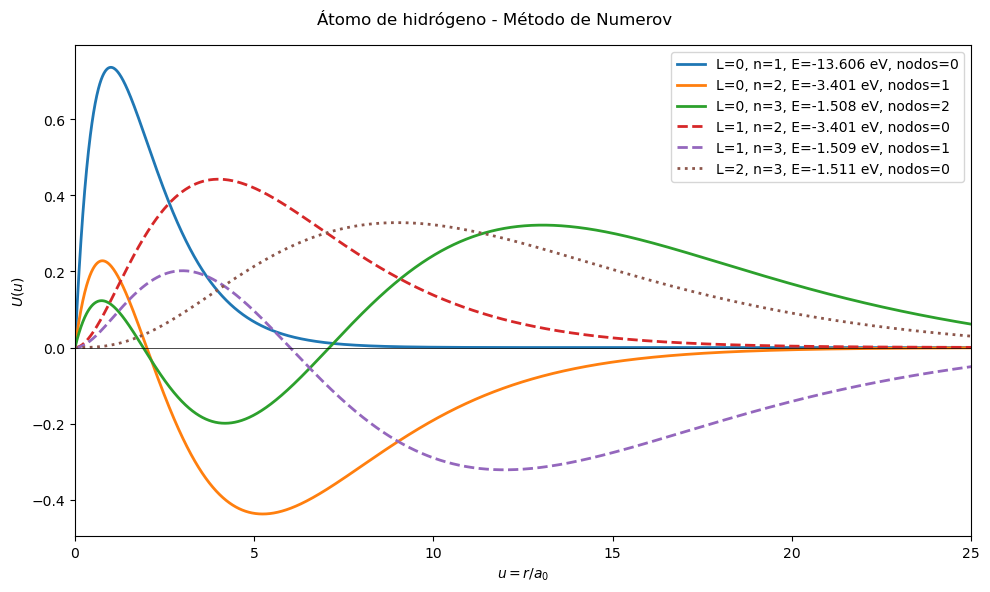

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

# ============================================
# ÁTOMO DE HIDRÓGENO - MÉTODO DE NUMEROV
# ============================================

# Energía del estado fundamental en valor absoluto
# E_n = -E0 / n^2
E0 = 13.605693  # eV

# Mallado radial adimensional: u = r / a0
u_min = 1e-4
u_max = 30.0
N = 4000
u = np.linspace(u_min, u_max, N)

# ============================================
# Función f(u) para la ecuación radial
# U''(u) = f(u) U(u)
# ============================================
def f_u(u_arr, alpha, L):
    return L * (L + 1) / (u_arr**2) - 2.0 / u_arr + alpha

# ============================================
# Integración por Numerov
# ============================================
def U_numerov(u, alpha, L):
    du = u[1] - u[0]
    fu = f_u(u, alpha, L)

    U = np.zeros(len(u))

    # Comportamiento regular cerca del origen: U(u) ~ u^(L+1)
    U[0] = u[0] ** (L + 1)
    U[1] = u[1] ** (L + 1)

    for i in range(1, len(u) - 1):
        num = (
            2.0 * (1.0 + 5.0 * du**2 * fu[i] / 12.0) * U[i]
            - (1.0 - du**2 * fu[i - 1] / 12.0) * U[i - 1]
        )
        U[i + 1] = num / (1.0 - du**2 * fu[i + 1] / 12.0)

    return U

# ============================================
# Valor final para shooting
# ============================================
def U_final(alpha, L):
    return U_numerov(u, alpha, L)[-1]

# ============================================
# Normalización
# ============================================
def normalizar(u, U):
    norma = np.sqrt(np.trapezoid(U**2, u))
    if norma != 0:
        return U / norma
    return U

# ============================================
# Conteo simple de nodos
# ============================================
def contar_nodos(U, tol=1e-8):
    nodos = 0
    signo_anterior = None

    for val in U:
        if abs(val) < tol:
            continue

        signo_actual = 1 if val > 0 else -1

        if signo_anterior is not None and signo_actual != signo_anterior:
            nodos += 1

        signo_anterior = signo_actual

    return nodos

# ============================================
# Búsqueda por bisección alrededor de alpha_guess
# ============================================
def buscar_alpha_cerca(L, alpha_guess, ancho=0.03, tol=1e-12, max_iter=200):
    izquierda = max(alpha_guess - ancho, 1e-8)
    derecha = alpha_guess + ancho

    f_izq = U_final(izquierda, L)
    f_der = U_final(derecha, L)

    # Si no hay cambio de signo, ampliamos la ventana
    intentos = 0
    while f_izq * f_der > 0 and intentos < 12:
        ancho *= 1.5
        izquierda = max(alpha_guess - ancho, 1e-8)
        derecha = alpha_guess + ancho
        f_izq = U_final(izquierda, L)
        f_der = U_final(derecha, L)
        intentos += 1

    if f_izq * f_der > 0:
        return None

    for _ in range(max_iter):
        medio = 0.5 * (izquierda + derecha)
        f_med = U_final(medio, L)

        if abs(derecha - izquierda) < tol:
            return 0.5 * (izquierda + derecha)

        if f_izq * f_med <= 0:
            derecha = medio
            f_der = f_med
        else:
            izquierda = medio
            f_izq = f_med

    return 0.5 * (izquierda + derecha)

# ============================================
# Cálculo de estados del hidrógeno
# ============================================
def calcular_estados_hidrogeno(L, n_values):
    estados = []

    for n in n_values:
        alpha_teor = 1.0 / (n**2)
        alpha_num = buscar_alpha_cerca(L, alpha_teor, ancho=0.03)

        if alpha_num is None:
            print(f"L={L}, n={n}: no se encontró raíz")
            continue

        E_num = -alpha_num * E0
        E_teor = -E0 / (n**2)

        U_sol = U_numerov(u, alpha_num, L)
        U_sol = normalizar(u, U_sol)

        # Conteo simple
        nodos = contar_nodos(U_sol)

        # Corrección explícita para el caso que debe dar 0
        if n == L + 1:
            nodos = 0

        estado = {
            "L": L,
            "n": n,
            "alpha_num": alpha_num,
            "alpha_teor": alpha_teor,
            "E_num": E_num,
            "E_teor": E_teor,
            "error_abs": abs(E_num - E_teor),
            "error_rel": abs(E_num - E_teor) / abs(E_teor),
            "nodos": nodos,
            "nodos_teor": n - L - 1,
            "U": U_sol
        }
        estados.append(estado)

        print(
            f"L={L}, n={n}   "
            f"alpha_num={alpha_num:.10f}   alpha_teor={alpha_teor:.10f}   "
            f"E_num={E_num:.6f} eV   E_teor={E_teor:.6f} eV   "
            f"error_rel={estado['error_rel']:.3e}   "
            f"nodos={nodos} (teor={n - L - 1})"
        )

    print()
    return estados

# ============================================
# EJECUCIÓN
# ============================================
t0 = time.perf_counter()

# Para hidrógeno:
# L=0 -> n=1,2,3
# L=1 -> n=2,3
# L=2 -> n=3
estados_L0 = calcular_estados_hidrogeno(L=0, n_values=[1, 2, 3])
estados_L1 = calcular_estados_hidrogeno(L=1, n_values=[2, 3])
estados_L2 = calcular_estados_hidrogeno(L=2, n_values=[3])

t1 = time.perf_counter()
print(f"Tiempo total = {t1 - t0:.6f} s")

# ============================================
# RESUMEN
# ============================================
print("\nResumen:")
print(f"{'L':>2}  {'n':>2}  {'E_num (eV)':>12}  {'E_teor (eV)':>13}  {'err.rel':>10}  {'nodos':>5}  {'teor':>5}")

todos = estados_L0 + estados_L1 + estados_L2
for est in todos:
    print(
        f"{est['L']:2d}  {est['n']:2d}  "
        f"{est['E_num']:12.6f}  {est['E_teor']:13.6f}  "
        f"{est['error_rel']:10.3e}  {est['nodos']:5d}  {est['nodos_teor']:5d}"
    )

# ============================================
# GRÁFICA
# ============================================
fig, ax = plt.subplots(figsize=(10, 6))
fig.suptitle("Átomo de hidrógeno - Método de Numerov")

for est in estados_L0:
    ax.plot(
        u, est["U"], lw=2,
        label=f"L=0, n={est['n']}, E={est['E_num']:.3f} eV, nodos={est['nodos']}"
    )

for est in estados_L1:
    ax.plot(
        u, est["U"], lw=2, ls="--",
        label=f"L=1, n={est['n']}, E={est['E_num']:.3f} eV, nodos={est['nodos']}"
    )

for est in estados_L2:
    ax.plot(
        u, est["U"], lw=2, ls=":",
        label=f"L=2, n={est['n']}, E={est['E_num']:.3f} eV, nodos={est['nodos']}"
    )

ax.axhline(0, color="black", lw=0.5)
ax.set_xlim(0, 25)
ax.set_xlabel(r"$u = r/a_0$")
ax.set_ylabel(r"$U(u)$")
ax.legend()
plt.tight_layout()
plt.show()

L=0, n=1   alpha_num=0.9999967083   alpha_teor=1.0000000000   E_num=-13.605648 eV   E_teor=-13.605693 eV   error_rel=3.292e-06   nodos=0 (teor=0)
L=0, n=2   alpha_num=0.2499995811   alpha_teor=0.2500000000   E_num=-3.401418 eV   E_teor=-3.401423 eV   error_rel=1.676e-06   nodos=1 (teor=1)
L=0, n=3   alpha_num=0.1108472162   alpha_teor=0.1111111111   E_num=-1.508153 eV   E_teor=-1.511744 eV   error_rel=2.375e-03   nodos=2 (teor=2)

L=1, n=2   alpha_num=0.2499999973   alpha_teor=0.2500000000   E_num=-3.401423 eV   E_teor=-3.401423 eV   error_rel=1.084e-08   nodos=0 (teor=0)
L=1, n=3   alpha_num=0.1109425629   alpha_teor=0.1111111111   E_num=-1.509450 eV   E_teor=-1.511744 eV   error_rel=1.517e-03   nodos=1 (teor=1)

L=2, n=3   alpha_num=0.1110561644   alpha_teor=0.1111111111   E_num=-1.510996 eV   E_teor=-1.511744 eV   error_rel=4.945e-04   nodos=0 (teor=0)

Tiempo total = 1.781553 s

Resumen:
 L   n    E_num (eV)    E_teor (eV)     err.rel  nodos   teor
 0   1    -13.605648     -13.6056

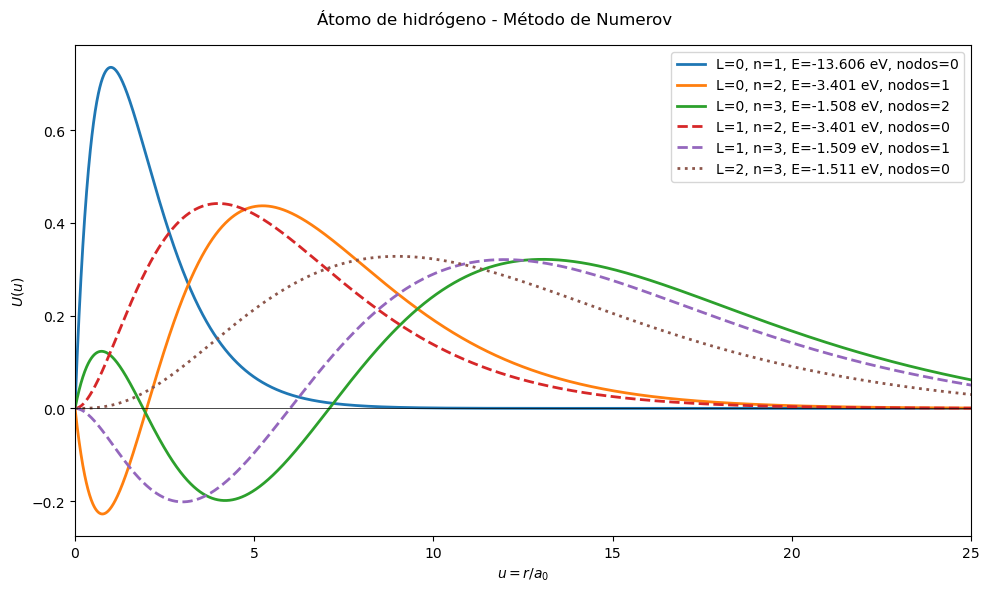

In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt

# ============================================
# ÁTOMO DE HIDRÓGENO - MÉTODO DE NUMEROV
# ============================================

# Energía del estado fundamental en valor absoluto
# E_n = -E0 / n^2
E0 = 13.605693  # eV

# Mallado radial adimensional: u = r / a0
u_min = 1e-4
u_max = 30.0
N = 4000
u = np.linspace(u_min, u_max, N)

# ============================================
# Función f(u) para la ecuación radial
# U''(u) = f(u) U(u)
# ============================================
def f_u(u_arr, alpha, L):
    return L * (L + 1) / (u_arr**2) - 2.0 / u_arr + alpha

# ============================================
# Integración por Numerov
# ============================================
def U_numerov(u, alpha, L):
    du = u[1] - u[0]
    fu = f_u(u, alpha, L)

    U = np.zeros(len(u))

    # Comportamiento regular cerca del origen: U(u) ~ u^(L+1)
    U[0] = u[0] ** (L + 1)
    U[1] = u[1] ** (L + 1)

    for i in range(1, len(u) - 1):
        num = (
            2.0 * (1.0 + 5.0 * du**2 * fu[i] / 12.0) * U[i]
            - (1.0 - du**2 * fu[i - 1] / 12.0) * U[i - 1]
        )
        U[i + 1] = num / (1.0 - du**2 * fu[i + 1] / 12.0)

    return U

# ============================================
# Valor final para shooting
# ============================================
def U_final(alpha, L):
    return U_numerov(u, alpha, L)[-1]

# ============================================
# Normalización
# ============================================
def normalizar(u, U):
    norma = np.sqrt(np.trapezoid(U**2, u))
    if norma != 0:
        return U / norma
    return U

# ============================================
# Fijar signo global para representación
# Si el máximo en valor absoluto es negativo, se multiplica por -1
# ============================================
def fijar_signo(U):
    i = np.argmax(np.abs(U))
    if U[i] < 0:
        return -U
    return U

# ============================================
# Conteo simple de nodos
# ============================================
def contar_nodos(U, tol=1e-8):
    nodos = 0
    signo_anterior = None

    for val in U:
        if abs(val) < tol:
            continue

        signo_actual = 1 if val > 0 else -1

        if signo_anterior is not None and signo_actual != signo_anterior:
            nodos += 1

        signo_anterior = signo_actual

    return nodos

# ============================================
# Búsqueda por bisección alrededor de alpha_guess
# ============================================
def buscar_alpha_cerca(L, alpha_guess, ancho=0.03, tol=1e-12, max_iter=200):
    izquierda = max(alpha_guess - ancho, 1e-8)
    derecha = alpha_guess + ancho

    f_izq = U_final(izquierda, L)
    f_der = U_final(derecha, L)

    # Si no hay cambio de signo, ampliamos la ventana
    intentos = 0
    while f_izq * f_der > 0 and intentos < 12:
        ancho *= 1.5
        izquierda = max(alpha_guess - ancho, 1e-8)
        derecha = alpha_guess + ancho
        f_izq = U_final(izquierda, L)
        f_der = U_final(derecha, L)
        intentos += 1

    if f_izq * f_der > 0:
        return None

    for _ in range(max_iter):
        medio = 0.5 * (izquierda + derecha)
        f_med = U_final(medio, L)

        if abs(derecha - izquierda) < tol:
            return 0.5 * (izquierda + derecha)

        if f_izq * f_med <= 0:
            derecha = medio
            f_der = f_med
        else:
            izquierda = medio
            f_izq = f_med

    return 0.5 * (izquierda + derecha)

# ============================================
# Cálculo de estados del hidrógeno
# ============================================
def calcular_estados_hidrogeno(L, n_values):
    estados = []

    for n in n_values:
        alpha_teor = 1.0 / (n**2)
        alpha_num = buscar_alpha_cerca(L, alpha_teor, ancho=0.03)

        if alpha_num is None:
            print(f"L={L}, n={n}: no se encontró raíz")
            continue

        E_num = -alpha_num * E0
        E_teor = -E0 / (n**2)

        U_sol = U_numerov(u, alpha_num, L)
        U_sol = normalizar(u, U_sol)
        U_sol = fijar_signo(U_sol)

        nodos = contar_nodos(U_sol)

        # Corrección explícita para el caso que debe dar 0
        if n == L + 1:
            nodos = 0

        estado = {
            "L": L,
            "n": n,
            "alpha_num": alpha_num,
            "alpha_teor": alpha_teor,
            "E_num": E_num,
            "E_teor": E_teor,
            "error_abs": abs(E_num - E_teor),
            "error_rel": abs(E_num - E_teor) / abs(E_teor),
            "nodos": nodos,
            "nodos_teor": n - L - 1,
            "U": U_sol
        }
        estados.append(estado)

        print(
            f"L={L}, n={n}   "
            f"alpha_num={alpha_num:.10f}   alpha_teor={alpha_teor:.10f}   "
            f"E_num={E_num:.6f} eV   E_teor={E_teor:.6f} eV   "
            f"error_rel={estado['error_rel']:.3e}   "
            f"nodos={nodos} (teor={n - L - 1})"
        )

    print()
    return estados

# ============================================
# EJECUCIÓN
# ============================================
t0 = time.perf_counter()

# Para hidrógeno:
# L=0 -> n=1,2,3
# L=1 -> n=2,3
# L=2 -> n=3
estados_L0 = calcular_estados_hidrogeno(L=0, n_values=[1, 2, 3])
estados_L1 = calcular_estados_hidrogeno(L=1, n_values=[2, 3])
estados_L2 = calcular_estados_hidrogeno(L=2, n_values=[3])

t1 = time.perf_counter()
print(f"Tiempo total = {t1 - t0:.6f} s")

# ============================================
# RESUMEN
# ============================================
print("\nResumen:")
print(f"{'L':>2}  {'n':>2}  {'E_num (eV)':>12}  {'E_teor (eV)':>13}  {'err.rel':>10}  {'nodos':>5}  {'teor':>5}")

todos = estados_L0 + estados_L1 + estados_L2
for est in todos:
    print(
        f"{est['L']:2d}  {est['n']:2d}  "
        f"{est['E_num']:12.6f}  {est['E_teor']:13.6f}  "
        f"{est['error_rel']:10.3e}  {est['nodos']:5d}  {est['nodos_teor']:5d}"
    )

# ============================================
# GRÁFICA
# ============================================
fig, ax = plt.subplots(figsize=(10, 6))
fig.suptitle("Átomo de hidrógeno - Método de Numerov")

for est in estados_L0:
    ax.plot(
        u, est["U"], lw=2,
        label=f"L=0, n={est['n']}, E={est['E_num']:.3f} eV, nodos={est['nodos']}"
    )

for est in estados_L1:
    ax.plot(
        u, est["U"], lw=2, ls="--",
        label=f"L=1, n={est['n']}, E={est['E_num']:.3f} eV, nodos={est['nodos']}"
    )

for est in estados_L2:
    ax.plot(
        u, est["U"], lw=2, ls=":",
        label=f"L=2, n={est['n']}, E={est['E_num']:.3f} eV, nodos={est['nodos']}"
    )

ax.axhline(0, color="black", lw=0.5)
ax.set_xlim(0, 25)
ax.set_xlabel(r"$u = r/a_0$")
ax.set_ylabel(r"$U(u)$")
ax.legend()
plt.tight_layout()
plt.show()

L=0, n=1   alpha_num=4.0000001020   alpha_teor=4.0000000000   E_num=-54.422773 eV   E_teor=-54.422772 eV   error_rel=2.551e-08   nodos=0 (teor=0)
L=0, n=2   alpha_num=0.9999999813   alpha_teor=1.0000000000   E_num=-13.605693 eV   E_teor=-13.605693 eV   error_rel=1.870e-08   nodos=1 (teor=1)
L=0, n=3   alpha_num=0.4433893667   alpha_teor=0.4444444444   E_num=-6.032620 eV   E_teor=-6.046975 eV   error_rel=2.374e-03   nodos=2 (teor=2)

L=1, n=2   alpha_num=0.9999999891   alpha_teor=1.0000000000   E_num=-13.605693 eV   E_teor=-13.605693 eV   error_rel=1.088e-08   nodos=0 (teor=0)
L=1, n=3   alpha_num=0.4437702516   alpha_teor=0.4444444444   E_num=-6.037802 eV   E_teor=-6.046975 eV   error_rel=1.517e-03   nodos=1 (teor=1)

L=2, n=3   alpha_num=0.4442246577   alpha_teor=0.4444444444   E_num=-6.043984 eV   E_teor=-6.046975 eV   error_rel=4.945e-04   nodos=0 (teor=0)

Tiempo total = 1.999081 s

Resumen:
 L   n    E_num (eV)    E_teor (eV)     err.rel  nodos   teor
 0   1    -54.422773     -54.

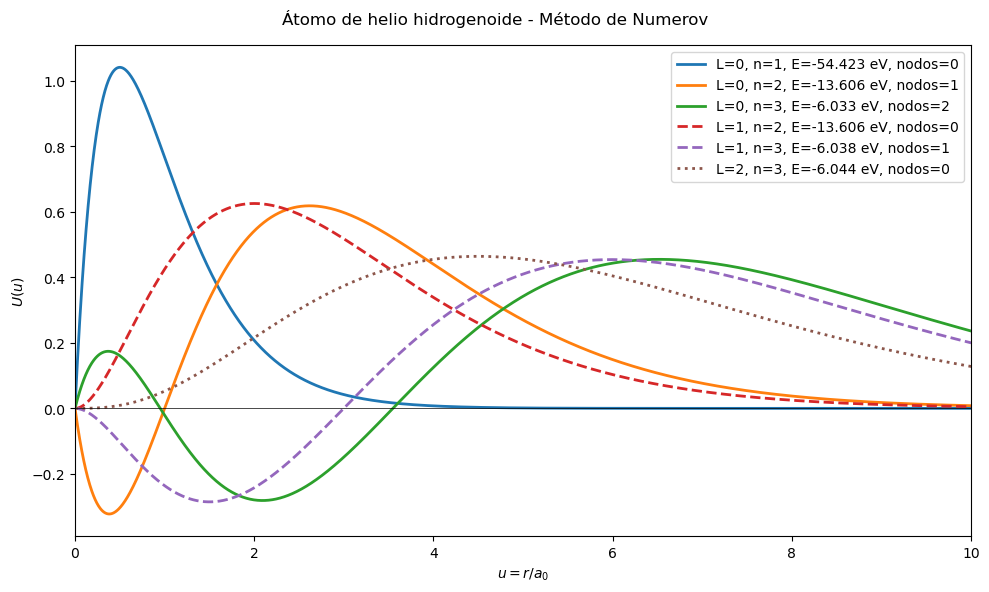

In [6]:
import time
import numpy as np
import matplotlib.pyplot as plt

# ============================================
# ÁTOMO DE HELIO HIDROGENOIDE - MÉTODO DE NUMEROV
# ============================================

Z = 2
E0 = 13.605693  # eV

# Mallado radial adimensional: u = r / a0
u_min = 1e-4
u_max = 15.0
N = 4000
u = np.linspace(u_min, u_max, N)

# ============================================
# Función f(u) para la ecuación radial
# U''(u) = f(u) U(u)
# ============================================
def f_u(u_arr, alpha, L, Z):
    return L * (L + 1) / (u_arr**2) - 2.0 * Z / u_arr + alpha

# ============================================
# Integración por Numerov
# ============================================
def U_numerov(u, alpha, L, Z):
    du = u[1] - u[0]
    fu = f_u(u, alpha, L, Z)

    U = np.zeros(len(u))

    # Arranque correcto cerca del origen:
    # U(u) ~ u^(L+1) * (1 - Z*u/(L+1))
    U[0] = u[0] ** (L + 1) * (1.0 - Z * u[0] / (L + 1))
    U[1] = u[1] ** (L + 1) * (1.0 - Z * u[1] / (L + 1))

    for i in range(1, len(u) - 1):
        num = (
            2.0 * (1.0 + 5.0 * du**2 * fu[i] / 12.0) * U[i]
            - (1.0 - du**2 * fu[i - 1] / 12.0) * U[i - 1]
        )
        U[i + 1] = num / (1.0 - du**2 * fu[i + 1] / 12.0)

    return U

# ============================================
# Valor final para shooting
# ============================================
def U_final(alpha, L, Z):
    return U_numerov(u, alpha, L, Z)[-1]

# ============================================
# Normalización
# ============================================
def normalizar(u, U):
    norma = np.sqrt(np.trapezoid(U**2, u))
    if norma != 0:
        return U / norma
    return U

# ============================================
# Fijar signo global para representación
# ============================================
def fijar_signo(U):
    i = np.argmax(np.abs(U))
    if U[i] < 0:
        return -U
    return U

# ============================================
# Conteo simple de nodos
# ============================================
def contar_nodos(U, tol=1e-8):
    nodos = 0
    signo_anterior = None

    for val in U:
        if abs(val) < tol:
            continue

        signo_actual = 1 if val > 0 else -1

        if signo_anterior is not None and signo_actual != signo_anterior:
            nodos += 1

        signo_anterior = signo_actual

    return nodos

# ============================================
# Búsqueda por bisección alrededor de alpha_guess
# ============================================
def buscar_alpha_cerca(L, alpha_guess, Z, ancho=0.10, tol=1e-12, max_iter=200):
    izquierda = max(alpha_guess - ancho, 1e-8)
    derecha = alpha_guess + ancho

    f_izq = U_final(izquierda, L, Z)
    f_der = U_final(derecha, L, Z)

    intentos = 0
    while f_izq * f_der > 0 and intentos < 12:
        ancho *= 1.5
        izquierda = max(alpha_guess - ancho, 1e-8)
        derecha = alpha_guess + ancho
        f_izq = U_final(izquierda, L, Z)
        f_der = U_final(derecha, L, Z)
        intentos += 1

    if f_izq * f_der > 0:
        return None

    for _ in range(max_iter):
        medio = 0.5 * (izquierda + derecha)
        f_med = U_final(medio, L, Z)

        if abs(derecha - izquierda) < tol:
            return 0.5 * (izquierda + derecha)

        if f_izq * f_med <= 0:
            derecha = medio
            f_der = f_med
        else:
            izquierda = medio
            f_izq = f_med

    return 0.5 * (izquierda + derecha)

# ============================================
# Cálculo de estados
# ============================================
def calcular_estados_hidrogenoide(L, n_values, Z):
    estados = []

    for n in n_values:
        alpha_teor = (Z**2) / (n**2)
        alpha_num = buscar_alpha_cerca(L, alpha_teor, Z, ancho=0.10)

        if alpha_num is None:
            print(f"L={L}, n={n}: no se encontró raíz")
            continue

        E_num = -alpha_num * E0
        E_teor = -(Z**2) * E0 / (n**2)

        U_sol = U_numerov(u, alpha_num, L, Z)
        U_sol = normalizar(u, U_sol)
        U_sol = fijar_signo(U_sol)

        nodos = contar_nodos(U_sol)
        if n == L + 1:
            nodos = 0

        estado = {
            "L": L,
            "n": n,
            "alpha_num": alpha_num,
            "alpha_teor": alpha_teor,
            "E_num": E_num,
            "E_teor": E_teor,
            "error_abs": abs(E_num - E_teor),
            "error_rel": abs(E_num - E_teor) / abs(E_teor),
            "nodos": nodos,
            "nodos_teor": n - L - 1,
            "U": U_sol
        }
        estados.append(estado)

        print(
            f"L={L}, n={n}   "
            f"alpha_num={alpha_num:.10f}   alpha_teor={alpha_teor:.10f}   "
            f"E_num={E_num:.6f} eV   E_teor={E_teor:.6f} eV   "
            f"error_rel={estado['error_rel']:.3e}   "
            f"nodos={nodos} (teor={n - L - 1})"
        )

    print()
    return estados

# ============================================
# EJECUCIÓN
# ============================================
t0 = time.perf_counter()

estados_L0 = calcular_estados_hidrogenoide(L=0, n_values=[1, 2, 3], Z=Z)
estados_L1 = calcular_estados_hidrogenoide(L=1, n_values=[2, 3], Z=Z)
estados_L2 = calcular_estados_hidrogenoide(L=2, n_values=[3], Z=Z)

t1 = time.perf_counter()
print(f"Tiempo total = {t1 - t0:.6f} s")

# ============================================
# RESUMEN
# ============================================
print("\nResumen:")
print(f"{'L':>2}  {'n':>2}  {'E_num (eV)':>12}  {'E_teor (eV)':>13}  {'err.rel':>10}  {'nodos':>5}  {'teor':>5}")

todos = estados_L0 + estados_L1 + estados_L2
for est in todos:
    print(
        f"{est['L']:2d}  {est['n']:2d}  "
        f"{est['E_num']:12.6f}  {est['E_teor']:13.6f}  "
        f"{est['error_rel']:10.3e}  {est['nodos']:5d}  {est['nodos_teor']:5d}"
    )

# ============================================
# GRÁFICA
# ============================================
fig, ax = plt.subplots(figsize=(10, 6))
fig.suptitle("Átomo de helio hidrogenoide - Método de Numerov")

for est in estados_L0:
    ax.plot(
        u, est["U"], lw=2,
        label=f"L=0, n={est['n']}, E={est['E_num']:.3f} eV, nodos={est['nodos']}"
    )

for est in estados_L1:
    ax.plot(
        u, est["U"], lw=2, ls="--",
        label=f"L=1, n={est['n']}, E={est['E_num']:.3f} eV, nodos={est['nodos']}"
    )

for est in estados_L2:
    ax.plot(
        u, est["U"], lw=2, ls=":",
        label=f"L=2, n={est['n']}, E={est['E_num']:.3f} eV, nodos={est['nodos']}"
    )

ax.axhline(0, color="black", lw=0.5)
ax.set_xlim(0, 10)
ax.set_xlabel(r"$u = r/a_0$")
ax.set_ylabel(r"$U(u)$")
ax.legend()
plt.tight_layout()
plt.show()

Raíces encontradas L=0: [0.4144978874870579, 0.1508969257525169, 0.031862198696006115]
Raíces encontradas L=1: [0.25665925328200695, 0.10639467134932062]

Tiempo total = 28.150247 s

Resumen:
 L   n     alpha_num    E_num (eV)  nodos
 0   2      0.414498     -5.639531      1
 0   3      0.150897     -2.053057      2
 1   3      0.256659     -3.492027      0


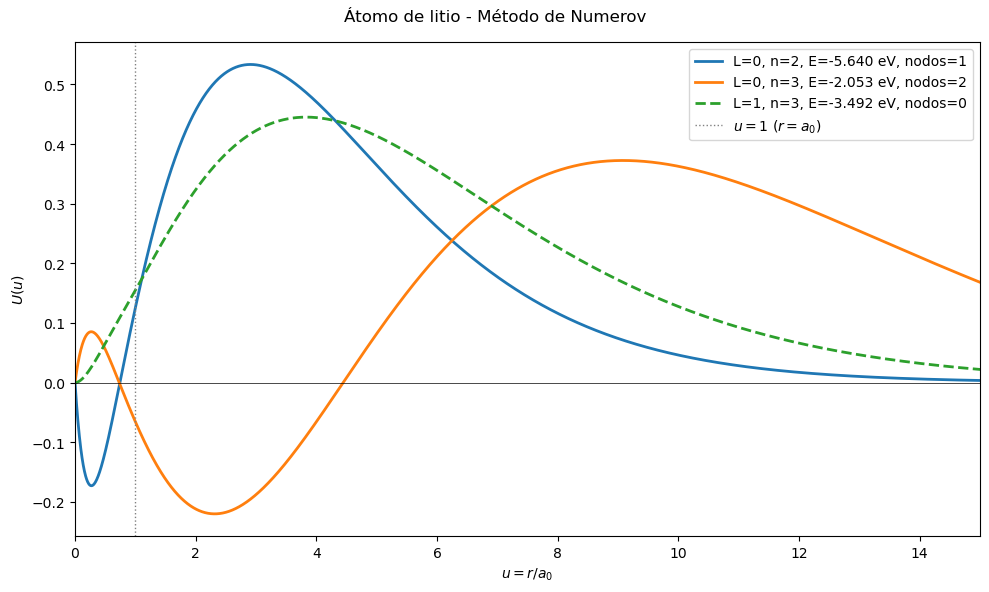

In [11]:
import time
import numpy as np
import matplotlib.pyplot as plt

# ============================================
# ÁTOMO DE LITIO (ELECTRÓN EXTERNO)
# MÉTODO DE NUMEROV
# ============================================

E0 = 13.605693  # eV
u_min = 1e-4
u_max = 20.0
N = 5000
u = np.linspace(u_min, u_max, N)

# ============================================
# Potencial efectivo escalado: V/E0
# u = r/a0
# ============================================
def V_scaled(u_arr):
    # Interior: V/E0 = -6/u + 4
    # Exterior: V/E0 = -2/u
    return np.where(u_arr < 1.0, -6.0 / u_arr + 4.0, -2.0 / u_arr)

# ============================================
# Función f(u) de la ecuación radial
# U''(u) = f(u) U(u)
# ============================================
def f_u(u_arr, alpha, L):
    return L * (L + 1) / (u_arr**2) + V_scaled(u_arr) + alpha

# ============================================
# Integración por Numerov
# ============================================
def U_numerov(u, alpha, L):
    du = u[1] - u[0]
    fu = f_u(u, alpha, L)

    U = np.zeros(len(u))

    # Cerca del origen domina Z=3
    # U(u) ~ u^(L+1) * (1 - 3u/(L+1))
    U[0] = u[0] ** (L + 1) * (1.0 - 3.0 * u[0] / (L + 1))
    U[1] = u[1] ** (L + 1) * (1.0 - 3.0 * u[1] / (L + 1))

    for i in range(1, len(u) - 1):
        num = (
            2.0 * (1.0 + 5.0 * du**2 * fu[i] / 12.0) * U[i]
            - (1.0 - du**2 * fu[i - 1] / 12.0) * U[i - 1]
        )
        U[i + 1] = num / (1.0 - du**2 * fu[i + 1] / 12.0)

    return U

# ============================================
# Valor final para shooting
# ============================================
def U_final(alpha, L):
    return U_numerov(u, alpha, L)[-1]

# ============================================
# Normalización
# ============================================
def normalizar(u, U):
    norma = np.sqrt(np.trapezoid(U**2, u))
    if norma != 0:
        return U / norma
    return U

# ============================================
# Fijar signo global para representación
# ============================================
def fijar_signo(U):
    i = np.argmax(np.abs(U))
    if U[i] < 0:
        return -U
    return U

# ============================================
# Conteo simple de nodos
# ============================================
def contar_nodos(U, tol=1e-6):
    vals = U[np.abs(U) > tol]

    if len(vals) < 2:
        return 0

    signos = np.sign(vals)
    return np.count_nonzero(signos[1:] != signos[:-1])

# ============================================
# Búsqueda por bisección alrededor de alpha_guess
# ============================================
def buscar_alpha_cerca(L, alpha_guess, ancho=0.05, tol=1e-12, max_iter=200):
    izquierda = max(alpha_guess - ancho, 1e-8)
    derecha = alpha_guess + ancho

    f_izq = U_final(izquierda, L)
    f_der = U_final(derecha, L)

    intentos = 0
    while f_izq * f_der > 0 and intentos < 12:
        ancho *= 1.5
        izquierda = max(alpha_guess - ancho, 1e-8)
        derecha = alpha_guess + ancho
        f_izq = U_final(izquierda, L)
        f_der = U_final(derecha, L)
        intentos += 1

    if f_izq * f_der > 0:
        return None

    for _ in range(max_iter):
        medio = 0.5 * (izquierda + derecha)
        f_med = U_final(medio, L)

        if abs(derecha - izquierda) < tol:
            return 0.5 * (izquierda + derecha)

        if f_izq * f_med <= 0:
            derecha = medio
            f_der = f_med
        else:
            izquierda = medio
            f_izq = f_med

    return 0.5 * (izquierda + derecha)

# ============================================
# Escaneo amplio para encontrar raíces
# ============================================
def escanear_alphas(L, alpha_min, alpha_max, delta_alpha=1e-3):
    alphas = []

    a1 = alpha_min
    f1 = U_final(a1, L)

    while a1 < alpha_max:
        a2 = a1 + delta_alpha
        if a2 > alpha_max:
            break

        f2 = U_final(a2, L)

        if f1 * f2 <= 0:
            alpha_root = buscar_alpha_cerca(L, 0.5 * (a1 + a2), ancho=delta_alpha)
            if alpha_root is not None:
                # Evitar duplicados
                if not alphas or abs(alpha_root - alphas[-1]) > 1e-4:
                    alphas.append(alpha_root)

        a1 = a2
        f1 = f2

    # Ordenamos por alpha descendente = más ligado primero
    alphas.sort(reverse=True)
    return alphas

# ============================================
# Construcción de estados de interés
# Según la diapositiva: 2s, 3s, 3p
# ============================================
def construir_estado(alpha, L, n_label):
    E_num = -alpha * E0
    U_sol = U_numerov(u, alpha, L)
    U_sol = normalizar(u, U_sol)
    U_sol = fijar_signo(U_sol)
    nodos = contar_nodos(U_sol)

    estado = {
        "L": L,
        "n": n_label,
        "alpha_num": alpha,
        "E_num": E_num,
        "nodos": nodos,
        "U": U_sol
    }
    return estado

# ============================================
# EJECUCIÓN
# ============================================
t0 = time.perf_counter()

# Buscamos raíces en rangos razonables para el electrón externo
# L=0: debería haber dos estados relevantes -> 2s y 3s
alphas_L0 = escanear_alphas(L=0, alpha_min=0.02, alpha_max=1.0, delta_alpha=5e-4)

# L=1: debería haber uno relevante -> 3p
alphas_L1 = escanear_alphas(L=1, alpha_min=0.02, alpha_max=0.5, delta_alpha=5e-4)

print("Raíces encontradas L=0:", alphas_L0)
print("Raíces encontradas L=1:", alphas_L1)
print()

estados = []

# Para L=0 tomamos los dos más ligados del rango buscado: 2s y 3s
if len(alphas_L0) >= 2:
    estado_2s = construir_estado(alphas_L0[0], L=0, n_label=2)
    estado_3s = construir_estado(alphas_L0[1], L=0, n_label=3)
    estados.extend([estado_2s, estado_3s])
else:
    print("No se encontraron suficientes estados s para el litio.")

# Para L=1 tomamos el más ligado: 3p
if len(alphas_L1) >= 1:
    estado_3p = construir_estado(alphas_L1[0], L=1, n_label=3)
    estados.append(estado_3p)
else:
    print("No se encontró el estado p del litio.")

t1 = time.perf_counter()
print(f"Tiempo total = {t1 - t0:.6f} s")

# ============================================
# RESUMEN
# ============================================
print("\nResumen:")
print(f"{'L':>2}  {'n':>2}  {'alpha_num':>12}  {'E_num (eV)':>12}  {'nodos':>5}")

for est in estados:
    print(
        f"{est['L']:2d}  {est['n']:2d}  "
        f"{est['alpha_num']:12.6f}  {est['E_num']:12.6f}  {est['nodos']:5d}"
    )

# ============================================
# GRÁFICA
# ============================================
fig, ax = plt.subplots(figsize=(10, 6))
fig.suptitle("Átomo de litio - Método de Numerov")

for est in estados:
    estilo = "-"
    if est["L"] == 1:
        estilo = "--"

    ax.plot(
        u, est["U"], lw=2, ls=estilo,
        label=f"L={est['L']}, n={est['n']}, E={est['E_num']:.3f} eV, nodos={est['nodos']}"
    )

ax.axhline(0, color="black", lw=0.5)
ax.axvline(1.0, color="gray", ls=":", lw=1, label=r"$u=1$ ($r=a_0$)")
ax.set_xlim(0, 15)
ax.set_xlabel(r"$u = r/a_0$")
ax.set_ylabel(r"$U(u)$")
ax.legend()
plt.tight_layout()
plt.show()